# Latihan SVM (Kernel Linear): Perhitungan Manual & Scikit-Learn

- **Dataset**: Data Klasifikasi Kelulusan Ujian (*Study Hours*, *Sleep Hours*, *Passed Exam* — 8 sampel)
- **Referensi Materi**: [Latihan SVM (Notion)](https://app.notion.com/p/Latihan-SVM-Not-OK-28ce27a5dc7b8049ae05cd252dd60631)

**Support Vector Machine (SVM)** adalah salah satu algoritma *machine learning* yang efektif dan serbaguna untuk tugas **klasifikasi** dan **regresi**. Pada latihan ini kita berfokus pada SVM dengan **kernel linear**, yaitu metode yang mencari batas pemisah (*hyperplane*) linear terbaik antar kelas data.

### Keunggulan SVM
- Mampu menangani berbagai jenis data, termasuk citra (pengenalan wajah, pengelompokan gambar), teks (klasifikasi teks, analisis sentimen, deteksi spam), dan data tabular.
- Efektif dalam mengklasifikasikan data berpola **linear** maupun **non-linear** (dengan bantuan *kernel trick*).

---

## Konsep Dasar SVM

Inti dari SVM adalah menemukan **hyperplane optimal** yang memisahkan titik-titik data dari kelas berbeda dengan **margin terbesar** terhadap titik data terdekat dari setiap kelas. Titik data terdekat yang menentukan batas tersebut disebut **Support Vectors**.

### Ilustrasi & Representasi Data
Misalkan terdapat dua kelompok siswa ("lulus" dan "tidak lulus" ujian) berdasarkan **lama belajar** ($x_1$) dan **lama tidur** ($x_2$). Dalam klasifikasi biner SVM, kelas direpresentasikan secara numerik sebagai:
- Kelas positif (lulus ujian): **+1**
- Kelas negatif (tidak lulus ujian): **-1**

## Perhitungan Manual SVM (Kernel Linear)

Berikut langkah-langkah perhitungan manual untuk menemukan persamaan *hyperplane*:

### 1. Fungsi Umum SVM
Fungsi dasar *hyperplane* linear dalam ruang 2D adalah:
$$w_1 x_1 + w_2 x_2 + b = 0$$
dengan $x_1$ (*Study Hours*), $x_2$ (*Sleep Hours*), $w_1, w_2$ (bobot fitur), dan $b$ (bias / *intercept*). Persamaan pembatas masing-masing kelas menjadi:
- Kelas $+1$ (lulus): $w_1 x_1 + w_2 x_2 + b = 1$
- Kelas $-1$ (tidak lulus): $w_1 x_1 + w_2 x_2 + b = -1$

### 2. Identifikasi Support Vectors
Secara visual dipilih 4 titik terdekat dari masing-masing kelas sebagai *support vectors*: `(3, 7)` dan `(4, 6)` untuk kelas `+1`, serta `(1, 6)` dan `(2, 5)` untuk kelas `-1`.

### 3. Substitusi Koordinat ke Rumus
- Titik `(3, 7)`, kelas `+1`: $3w_1 + 7w_2 + b = 1$
- Titik `(4, 6)`, kelas `+1`: $4w_1 + 6w_2 + b = 1$
- Titik `(1, 6)`, kelas `-1`: $1w_1 + 6w_2 + b = -1$
- Titik `(2, 5)`, kelas `-1`: $2w_1 + 5w_2 + b = -1$

### 4. Reduksi Persamaan (Hubungan $w_1$ dan $w_2$)
- Kelas lulus: $(4w_1 + 6w_2 + b = 1) - (3w_1 + 7w_2 + b = 1) \Rightarrow w_1 - w_2 = 0 \Rightarrow w_1 = w_2$
- Kelas tidak lulus: $(2w_1 + 5w_2 + b = -1) - (1w_1 + 6w_2 + b = -1) \Rightarrow w_1 - w_2 = 0 \Rightarrow w_1 = w_2$

### 5. Penyelesaian untuk $w_1$, $w_2$, dan $b$
Substitusikan $w_1 = w_2$ ke salah satu persamaan dari tiap kelas:
1. $10w_1 + b = 1$
2. $7w_1 + b = -1$

Kurangkan persamaan (1) dengan (2):
$$(10w_1 + b) - (7w_1 + b) = 1 - (-1) \Rightarrow 3w_1 = 2 \Rightarrow w_1 = \frac{2}{3}$$
Karena $w_1 = w_2$, maka $w_2 = \frac{2}{3}$. Substitusi kembali ke persamaan (1):
$$10\left(\frac{2}{3}\right) + b = 1 \Rightarrow b = 1 - \frac{20}{3} = -\frac{17}{3}$$

### 6. Pembentukan Garis Batas (*Decision Boundary*)
$$\frac{2}{3}x_1 + \frac{2}{3}x_2 - \frac{17}{3} = 0 \Rightarrow 2x_1 + 2x_2 - 17 = 0 \Rightarrow x_2 = -x_1 + 8.5$$

### 7. Garis Toleransi (Margin)
Sesuai ilustrasi modul Notion untuk memvisualisasikan pita toleransi sejajar di sekitar garis batas:
- **Garis Margin Positif**: $x_2 = -x_1 + 9$
- **Garis Margin Negatif**: $x_2 = -x_1 + 8$

## Implementasi SVM dengan Python

### 1. Import Library & Persiapan Data
Kita mengimpor `numpy`, `matplotlib.pyplot`, dan modul `svm` dari `scikit-learn`, lalu menyiapkan dataset kelulusan ujian (`x1` sebagai *Study Hours*, `x2` sebagai *Sleep Hours*, dan `y` sebagai label kelulusan `+1` / `-1`).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import svm

# Dataset Klasifikasi Kelulusan Ujian
x1 = np.array([2, 1, 3, 1, 4, 2, 5, 2])  # Study Hours
x2 = np.array([8, 6, 7, 4, 6, 5, 7, 3])  # Sleep Hours
y = np.array([1, -1, 1, -1, 1, -1, 1, -1])  # Passed Exam

### 2. Visualisasi Garis Batas & Margin Hasil Perhitungan Manual
Sel di bawah memplot sebaran data latih beserta persamaan *decision boundary* ($x_2 = -x_1 + 8.5$) dan garis margin ($x_2 = -x_1 + 9$ serta $x_2 = -x_1 + 8$) hasil perhitungan manual.

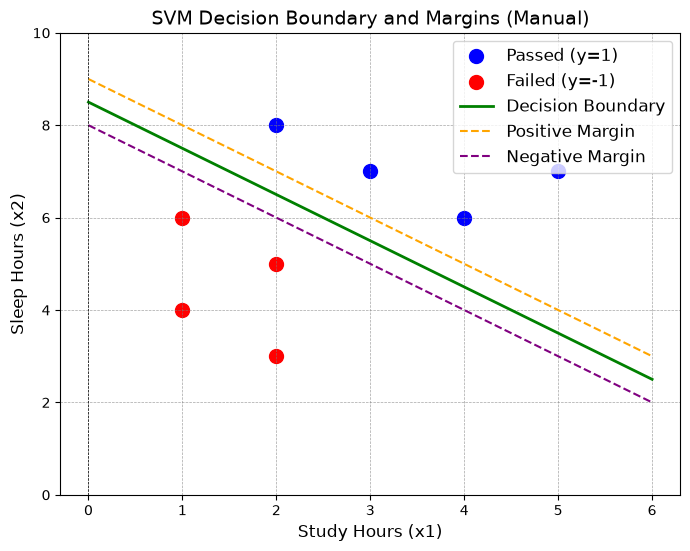

In [2]:
# Persamaan decision boundary dan margin dari perhitungan manual
x1_range = np.linspace(0, 6, 100)
decision_boundary = -x1_range + 8.5
margin_positive = -x1_range + 9
margin_negative = -x1_range + 8

# Plotting titik data
plt.figure(figsize=(8, 6))
plt.scatter(x1[y == 1], x2[y == 1], color='blue', label='Passed (y=1)', s=100)
plt.scatter(x1[y == -1], x2[y == -1], color='red', label='Failed (y=-1)', s=100)

# Plotting hyperplane dan margin
plt.plot(x1_range, decision_boundary, color='green', label='Decision Boundary', linewidth=2)
plt.plot(x1_range, margin_positive, color='orange', linestyle='--', label='Positive Margin', linewidth=1.5)
plt.plot(x1_range, margin_negative, color='purple', linestyle='--', label='Negative Margin', linewidth=1.5)

# Label dan grid
plt.title('SVM Decision Boundary and Margins (Manual)', fontsize=14)
plt.xlabel('Study Hours (x1)', fontsize=12)
plt.ylabel('Sleep Hours (x2)', fontsize=12)
plt.axhline(0, color='black', linewidth=0.5, linestyle='--')
plt.axvline(0, color='black', linewidth=0.5, linestyle='--')
plt.grid(color='gray', linestyle='--', linewidth=0.5, alpha=0.7)
plt.legend(fontsize=12)
plt.ylim(0, 10)
plt.show()

### 3. Membuat dan Melatih Model SVM dengan Scikit-Learn
Fitur `x1` dan `x2` digabungkan menjadi matriks 2D `X` menggunakan `np.column_stack((x1, x2))`. Kemudian kita membuat objek `svm.SVC(kernel='linear')`, melatihnya dengan `.fit(X, y)`, serta mengambil bobot `w = clf.coef_[0]` dan bias `b = clf.intercept_[0]` untuk membandingkan hasilnya dengan perhitungan manual.

In [3]:
# Menggabungkan x1 dan x2 menjadi array 2D sesuai format input Scikit-Learn
X = np.column_stack((x1, x2))

# Membuat dan melatih model SVM dengan kernel linear
clf = svm.SVC(kernel='linear')
clf.fit(X, y)

# Mengambil parameter decision boundary (hyperplane)
w = clf.coef_[0]
b = clf.intercept_[0]

print(f'Bobot (w): w1 = {w[0]:.4f}, w2 = {w[1]:.4f}')
print(f'Bias (b): {b:.4f}')

Bobot (w): w1 = 0.6667, w2 = 0.6667
Bias (b): -5.6667


### 4. Visualisasi Decision Boundary dari Scikit-Learn
Dengan menggunakan parameter `w` dan `b` hasil pelatihan `SVC(kernel='linear')`, garis *decision boundary* dihitung melalui $x_2 = -\frac{w_0 x_1 + b}{w_1}$ dan digambarkan pada grafik di bawah.

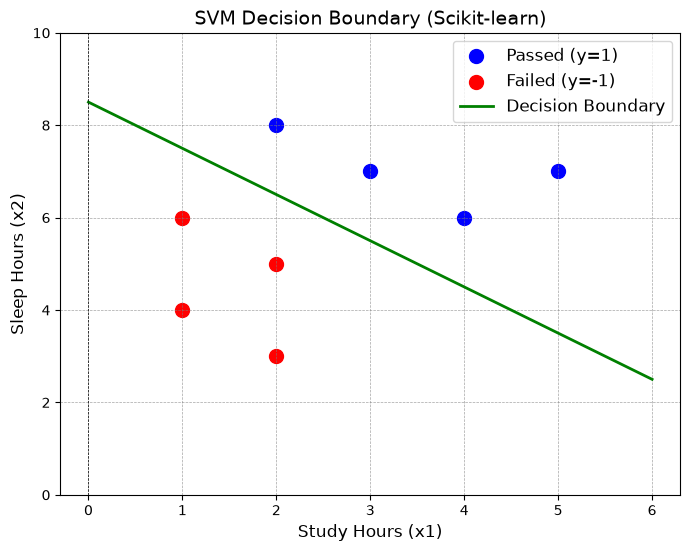

In [4]:
# Plotting titik data
plt.figure(figsize=(8, 6))
plt.scatter(x1[y == 1], x2[y == 1], color='blue', label='Passed (y=1)', s=100)
plt.scatter(x1[y == -1], x2[y == -1], color='red', label='Failed (y=-1)', s=100)

# Plot decision boundary hasil Scikit-Learn
x1_range = np.linspace(0, 6, 100)
decision_boundary_sklearn = -(w[0] * x1_range + b) / w[1]
plt.plot(x1_range, decision_boundary_sklearn, color='green', label='Decision Boundary', linewidth=2)

plt.title('SVM Decision Boundary (Scikit-learn)', fontsize=14)
plt.xlabel('Study Hours (x1)', fontsize=12)
plt.ylabel('Sleep Hours (x2)', fontsize=12)
plt.axhline(0, color='black', linewidth=0.5, linestyle='--')
plt.axvline(0, color='black', linewidth=0.5, linestyle='--')
plt.grid(color='gray', linestyle='--', linewidth=0.5, alpha=0.7)
plt.legend(fontsize=12)
plt.ylim(0, 10)
plt.show()

## Kesimpulan

Perhitungan manual maupun implementasi menggunakan `sklearn.svm.SVC(kernel='linear')` menghasilkan nilai parameter yang sama persis ($w_1 \approx 0.6667 = \frac{2}{3}$, $w_2 \approx 0.6667 = \frac{2}{3}$, dan $b \approx -5.6667 = -\frac{17}{3}$), sehingga garis batas keputusan (*decision boundary*) keduanya identik: $x_2 = -x_1 + 8.5$.